# 02 · Baselines explained

Run `tickercast baselines` first. Plain-language guide: [docs/08_baselines.md](../docs/08_baselines.md).

All scores are on the **validation years 2020–2021**. Models were trained on 2005–2019.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R = ROOT / "data/results"
scores = {t: pd.read_csv(R / f"baselines_val_scores_{t}.csv", index_col=0) for t in ["label_up_1d", "label_outperform_1d"]}
cols = ["accuracy", "train_auc", "auc", "daily_ic", "top_minus_bottom"]

## 1. Target "will it go up tomorrow?"

Look at **train_auc vs auc**: the LightGBM models score much higher on training data than on validation. That gap means they memorized.

In [2]:
scores["label_up_1d"][cols].sort_values("daily_ic", ascending=False).style.format(precision=4)

,accuracy,train_auc,auc,daily_ic,top_minus_bottom
logistic_all,0.5274,0.5481,0.5237,0.0183,0.0004
opposite_of_today,0.5173,nan,0.5187,0.0183,0.0003
lightgbm_stock_only,0.5272,0.5414,0.5257,0.0135,0.0001
logistic_stock_only,0.5299,0.5259,0.5308,0.0132,0.0005
lightgbm_no_macro,0.5260,0.7722,0.5316,0.0090,0.0000
same_as_today,0.4827,nan,0.4813,-0.0183,-0.0006
majority_class,0.5261,nan,0.5000,nan,nan
lightgbm_all,0.5261,0.6242,0.5181,nan,-0.0004


## 2. Target "will it beat the market tomorrow?"

Smaller train/validation gaps, and a clearly positive **daily IC** (stock-picking skill).

In [3]:
scores["label_outperform_1d"][cols].sort_values("daily_ic", ascending=False).style.format(precision=4)

,accuracy,train_auc,auc,daily_ic,top_minus_bottom
logistic_all,0.5074,0.5197,0.5134,0.0285,0.0010
lightgbm_stock_only,0.5109,0.5674,0.5172,0.0273,0.0012
logistic_stock_only,0.5094,0.5142,0.5119,0.0267,0.0007
lightgbm_no_macro,0.5134,0.5865,0.5152,0.0252,0.0009
lightgbm_all,0.5121,0.6045,0.5131,0.0195,0.0010
opposite_of_today,0.5064,nan,0.5065,0.0187,0.0001
same_as_today,0.4936,nan,0.4935,-0.0187,-0.0004
majority_class,0.5066,nan,0.5000,nan,nan


## 3. Stock-picking skill side by side

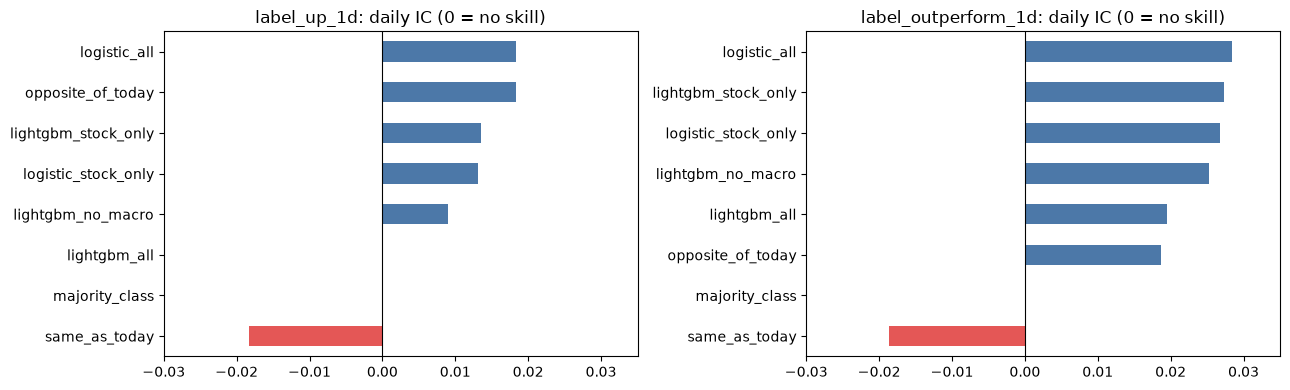

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (t, s) in zip(axes, scores.items()):
    ic = s["daily_ic"].fillna(0).sort_values()
    ic.plot.barh(ax=ax, color=["#E45756" if v <= 0 else "#4C78A8" for v in ic]); ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{t}: daily IC (0 = no skill)"); ax.set_xlim(-0.03, 0.035)
plt.tight_layout(); plt.show()

## 4. Does a higher score really mean a better stock?

Each day, split the ~480 stocks into 10 groups by the model's score (1 = liked least, 10 = liked most), then look at how each group did the next day compared with the market.

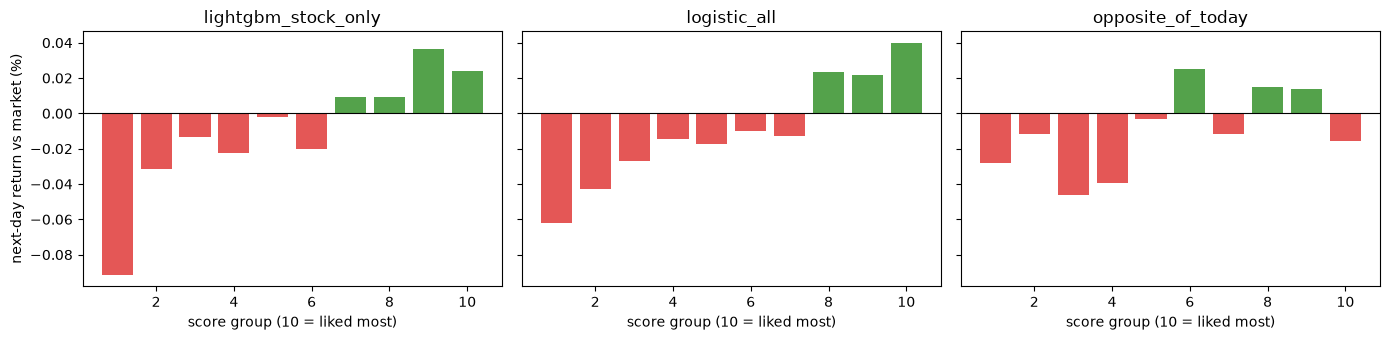

In [5]:
p = pd.read_parquet(R / "baselines_val_label_outperform_1d.parquet")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, m in zip(axes, ["lightgbm_stock_only", "logistic_all", "opposite_of_today"]):
    group = np.ceil(p.groupby("date")[m].rank(pct=True, method="first") * 10).clip(1, 10)
    avg = p.groupby(group)["fwd_excess_1d"].mean() * 100
    ax.bar(avg.index.astype(int), avg.values, color=["#E45756" if v < 0 else "#54A24B" for v in avg])
    ax.axhline(0, color="k", lw=0.8); ax.set_title(m); ax.set_xlabel("score group (10 = liked most)")
axes[0].set_ylabel("next-day return vs market (%)")
plt.tight_layout(); plt.show()

The ML models' bars mostly rise from left to right: higher score → better next day. The simple "opposite of today" rule is much messier.

## 5. Is the edge steady over time?

Daily top-10% minus bottom-10% return for the best LightGBM model, smoothed over 20 days. Above zero = the model's favorites beat its least favorites.

positive on 55% of days, average +0.115% per day


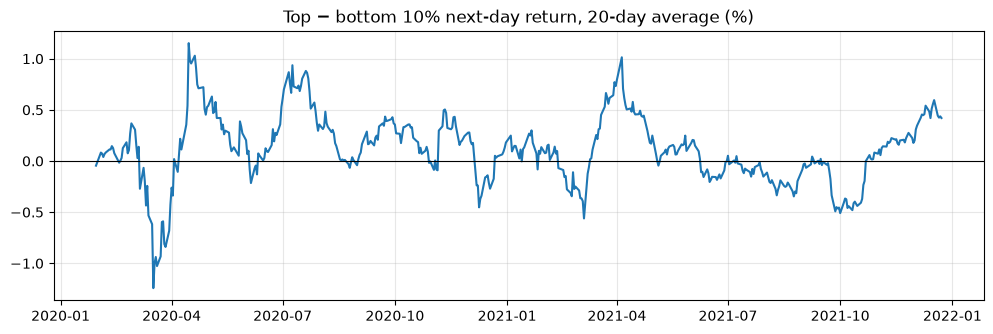

In [6]:
m = "lightgbm_stock_only"
pct = p.groupby("date")[m].rank(pct=True, method="first")
spread = (p[pct > 0.9].groupby("date")["fwd_excess_1d"].mean() - p[pct <= 0.1].groupby("date")["fwd_excess_1d"].mean()) * 100
print(f"positive on {(spread > 0).mean():.0%} of days, average {spread.mean():+.3f}% per day")
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(spread.index, spread.rolling(20).mean()); ax.axhline(0, color="k", lw=0.8)
ax.set_title("Top − bottom 10% next-day return, 20-day average (%)"); ax.grid(alpha=0.3); plt.show()

## 6. PatchTST speed on this Mac

In [7]:
bench = ROOT / "data/results/patchtst_benchmark.csv"
pd.read_csv(bench, index_col=0).style.format(precision=2) if bench.exists() else "run `tickercast benchmark`" 

,d_model,n_layers,n_heads,d_ff,params,samples_per_sec,minutes_per_epoch,epochs_in_50_min
size,,,,,,,,
small,64,2,4,128,135617,65213.86,0.37,133.82
medium,128,4,4,256,667265,30161.58,0.81,61.89
large,192,4,6,512,1591233,17083.84,1.43,35.06
xlarge,256,6,8,1024,5013249,6797.19,3.58,13.95
